# Variational Autoencoder (VAE) Implementation



## Cell 1: Install Required Packages


In [10]:

# Install required packages
%pip install torch torchvision numpy matplotlib seaborn scikit-learn tqdm


## Cell 2: Import Libraries


In [11]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
warnings.filterwarnings('ignore')

# Set device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Using device: {device}')


Using device: cuda


## Cell 3: Load dsprites Dataset


dsprites dataset loaded:
  - Total images: 737280
  - Image shape: (64, 64)
  - Image dtype: uint8

Showing 8 sample images from dsprites:


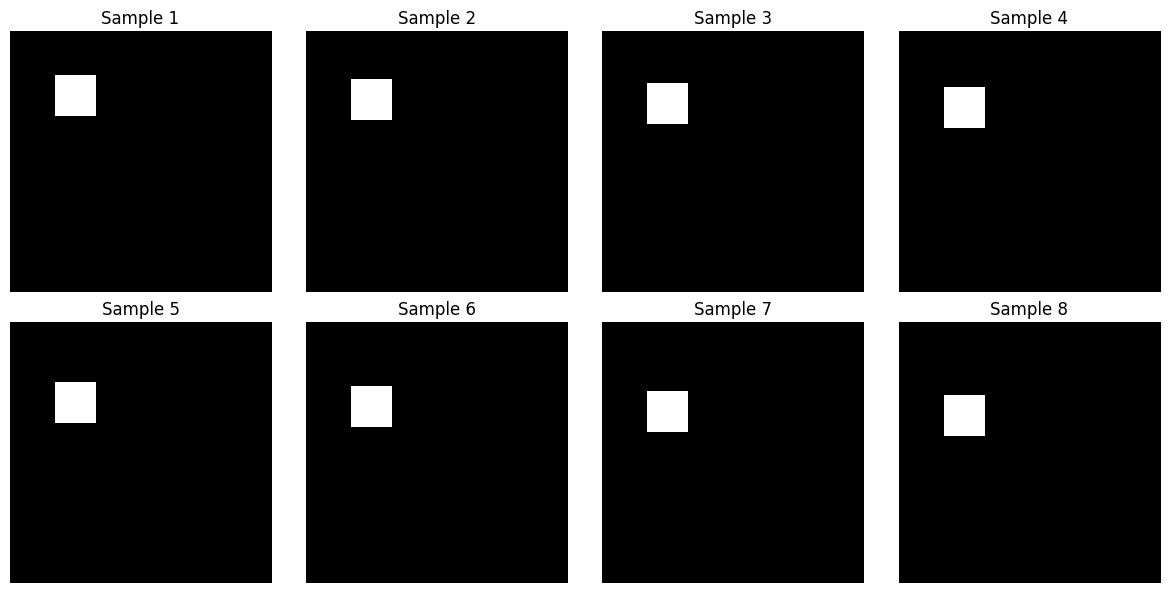

In [12]:
# Download and load dsprites dataset
# dsprites is available at: https://github.com/deepmind/dsprites-dataset

import os
import requests

def download_dsprites():
    """Download dsprites dataset if not already present"""
    url = 'https://github.com/deepmind/dsprites-dataset/raw/master/dsprites_ndarray_co1sh3sc6or40x32y32_64x64.npz'
    filename = 'dsprites_64x64.npz'

    if not os.path.exists(filename):
        print('Downloading dsprites dataset...')
        response = requests.get(url, stream=True)
        with open(filename, 'wb') as f:
            for chunk in response.iter_content(chunk_size=8192):
                f.write(chunk)
        print('Download complete!')
    else:
        print('dsprites dataset already exists.')

    return filename

def load_dsprites(filename='dsprites_64x64.npz'):
    """Load dsprites dataset"""
    if not os.path.exists(filename):
        filename = download_dsprites()

    dataset_zip = np.load(filename, allow_pickle=True, encoding='latin1')
    imgs = dataset_zip['imgs']  # Shape: (737280, 64, 64)

    print(f'dsprites dataset loaded:')
    print(f'  - Total images: {len(imgs)}')
    print(f'  - Image shape: {imgs[0].shape}')
    print(f'  - Image dtype: {imgs.dtype}')

    return imgs

# Load dataset
try:
    dsprites_images = load_dsprites()
    print('\nShowing 8 sample images from dsprites:')
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for i in range(8):
        ax = axes[i // 4, i % 4]
        ax.imshow(dsprites_images[i], cmap='gray')
        ax.set_title(f'Sample {i+1}')
        ax.axis('off')
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f'Error loading dsprites: {e}')
    print('Creating synthetic dataset for demonstration...')
    # Create synthetic 64x64 grayscale images
    dsprites_images = np.random.rand(10000, 64, 64).astype(np.float32)
    print(f'Created synthetic dataset with {len(dsprites_images)} images')


## Cell 4: Create Dataset Class


In [13]:
class DSpritesDataset(Dataset):
    """Dataset class for dsprites images"""

    def __init__(self, images, transform=None):
        """
        Args:
            images: numpy array of shape (N, 64, 64)
            transform: optional transform to apply
        """
        self.images = images.astype(np.float32)
        # Normalize to [0, 1] if not already
        if self.images.max() > 1.0:
            self.images = self.images / 255.0
        self.transform = transform

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        image = self.images[idx]

        # Add channel dimension: (64, 64) -> (1, 64, 64)
        image = torch.from_numpy(image).unsqueeze(0)

        if self.transform:
            image = self.transform(image)

        return image


## Cell 5: Define VAE Model Architecture (Table 1)


In [14]:
class VAE(nn.Module):
    """Variational Autoencoder with architecture from Table 1"""

    def __init__(self, h_dim=128, z_dim=32):
        """
        Args:
            h_dim: hidden dimension for the linear layer
            z_dim: latent space dimension (mu and logvar will have this size)
        """
        super(VAE, self).__init__()

        self.z_dim = z_dim

        # Encoder (from Table 1)
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size=4, stride=2, padding=1),  # 64x64 -> 32x32
            nn.ReLU(),
            nn.Conv2d(32, 64, kernel_size=4, stride=2, padding=1),  # 32x32 -> 16x16
            nn.ReLU(),
            nn.Conv2d(64, 128, kernel_size=4, stride=2, padding=1),  # 16x16 -> 8x8
            nn.ReLU(),
            nn.Flatten(),  # 128 * 8 * 8 = 8192
            nn.Linear(8192, h_dim)
        )

        # Latent space layers (mu and logvar)
        self.fc_mu = nn.Linear(h_dim, z_dim)
        self.fc_logvar = nn.Linear(h_dim, z_dim)

        # Decoder (from Table 1)
        self.decoder = nn.Sequential(
            nn.Linear(z_dim, 8192),
            nn.Unflatten(1, (128, 8, 8)),  # Reshape to (128, 8, 8)
            nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),  # 8x8 -> 16x16
            nn.ReLU(),
            nn.ConvTranspose2d(64, 32, kernel_size=4, stride=2, padding=1),  # 16x16 -> 32x32
            nn.ReLU(),
            nn.ConvTranspose2d(32, 1, kernel_size=4, stride=2, padding=1),  # 32x32 -> 64x64
            nn.Sigmoid()  # Output in [0, 1]
        )

    def encode(self, x):
        """Encode input to latent parameters"""
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        """Reparameterization trick"""
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z):
        """Decode latent vector to image"""
        return self.decoder(z)

    def forward(self, x):
        """Forward pass"""
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        recon_x = self.decode(z)
        return recon_x, mu, logvar

# Initialize model
h_dim = 128  # Hidden dimension
z_dim = 32   # Latent dimension
model = VAE(h_dim=h_dim, z_dim=z_dim).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Model initialized:')
print(f'  - Total parameters: {total_params:,}')
print(f'  - Trainable parameters: {trainable_params:,}')
print(f'  - Hidden dimension: {h_dim}')
print(f'  - Latent dimension: {z_dim}')


Model initialized:
  - Total parameters: 1,656,321
  - Trainable parameters: 1,656,321
  - Hidden dimension: 128
  - Latent dimension: 32


## Cell 6: Define Loss Function


In [15]:
def vae_loss(recon_x, x, mu, logvar, beta=1.0):
    """
    VAE loss function: Reconstruction Loss + KL Divergence

    Loss = -E[log p(x|z)] + D_KL(q(z|x) || p(z))

    Args:
        recon_x: reconstructed image
        x: original image
        mu: mean of latent distribution
        logvar: log variance of latent distribution
        beta: weight for KL divergence (default 1.0)
    """
    # Reconstruction loss (Binary Cross Entropy for images in [0,1])
    recon_loss = F.binary_cross_entropy(recon_x, x, reduction='sum')

    # KL divergence: -0.5 * sum(1 + logvar - mu^2 - exp(logvar))
    kl_loss = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())

    # Total loss
    total_loss = recon_loss + beta * kl_loss

    return total_loss, recon_loss, kl_loss


## Cell 7: Prepare DataLoader


In [16]:
# Create dataset and dataloader
# Use a subset of data for faster training (you can use all data)
n_samples = min(50000, len(dsprites_images))  # Use up to 50k samples
train_images = dsprites_images[:n_samples]

dataset = DSpritesDataset(train_images)
batch_size = 64  # You can adjust this
dataloader = DataLoader(dataset, batch_size=batch_size, shuffle=True, num_workers=2)

print(f'Dataset prepared:')
print(f'  - Total samples: {len(dataset)}')
print(f'  - Batch size: {batch_size}')
print(f'  - Number of batches: {len(dataloader)}')

# Show a sample batch
sample_batch = next(iter(dataloader))
print(f'\nSample batch shape: {sample_batch.shape}')


Dataset prepared:
  - Total samples: 50000
  - Batch size: 64
  - Number of batches: 782

Sample batch shape: torch.Size([64, 1, 64, 64])


## Cell 8: Training Function


In [21]:
def train_vae(model, dataloader, epochs=50, lr=0.001, device='cpu', beta=1.0):
    """
    Train VAE model

    Returns:
        history: dictionary with training metrics
    """
    # Hyperparameters from Table 2
    optimizer = optim.Adam(model.parameters(), lr=lr)

    # History for plotting
    history = {
        'total_loss': [],
        'recon_loss': [],
        'kl_loss': []
    }

    model.train()

    for epoch in range(epochs):
        epoch_total_loss = 0
        epoch_recon_loss = 0
        epoch_kl_loss = 0
        num_batches = 0

        progress_bar = tqdm(dataloader, desc=f'Epoch {epoch+1}/{epochs} (β={beta})')

        for batch_idx, x in enumerate(progress_bar):
            x = x.to(device)

            # Forward pass
            recon_x, mu, logvar = model(x)

            # Calculate loss with beta parameter
            total_loss, recon_loss, kl_loss = vae_loss(recon_x, x, mu, logvar, beta=beta)

            # Backward pass
            optimizer.zero_grad()
            total_loss.backward()
            optimizer.step()

            # Accumulate losses
            epoch_total_loss += total_loss.item()
            epoch_recon_loss += recon_loss.item()
            epoch_kl_loss += kl_loss.item()
            num_batches += 1

            # Update progress bar
            progress_bar.set_postfix({
                'Total': f'{total_loss.item()/len(x):.2f}',
                'Recon': f'{recon_loss.item()/len(x):.2f}',
                'KL': f'{kl_loss.item()/len(x):.2f}'
            })

        # Average losses for the epoch
        avg_total = epoch_total_loss / len(dataloader.dataset)
        avg_recon = epoch_recon_loss / len(dataloader.dataset)
        avg_kl = epoch_kl_loss / len(dataloader.dataset)

        history['total_loss'].append(avg_total)
        history['recon_loss'].append(avg_recon)
        history['kl_loss'].append(avg_kl)

        print(f'Epoch {epoch+1}/{epochs} (β={beta}) - Total: {avg_total:.2f}, Recon: {avg_recon:.2f}, KL: {avg_kl:.2f}')

    return history


In [22]:
# Train the model with hyperparameters from Table 2
print('=' * 60)
print('TRAINING VAE MODEL')
print('=' * 60)
print(f'Hyperparameters (from Table 2):')
print(f'  - Epochs: 50')
print(f'  - Optimizer: Adam')
print(f'  - Learning rate: 0.001')
print(f'  - Image dimension: (64, 64)')
print('=' * 60)

history = train_vae(
    model=model,
    dataloader=dataloader,
    epochs=50,  # From Table 2
    lr=0.001,   # From Table 2
    device=device,
    beta=1.0    # Explicitly set beta for VAE
)

print('\nTraining completed!')


TRAINING VAE MODEL
Hyperparameters (from Table 2):
  - Epochs: 50
  - Optimizer: Adam
  - Learning rate: 0.001
  - Image dimension: (64, 64)


Epoch 1/50 (β=1.0): 100%|██████████| 782/782 [00:09<00:00, 84.47it/s, Total=78.75, Recon=52.29, KL=26.46] 


Epoch 1/50 (β=1.0) - Total: 233.68, Recon: 192.10, KL: 41.58


Epoch 2/50 (β=1.0): 100%|██████████| 782/782 [00:08<00:00, 96.18it/s, Total=67.45, Recon=48.39, KL=19.05]


Epoch 2/50 (β=1.0) - Total: 72.99, Recon: 51.35, KL: 21.64


...

Epoch 48/50 (β=1.0) - Total: 33.44, Recon: 16.45, KL: 16.99


Epoch 49/50 (β=1.0): 100%|██████████| 782/782 [00:08<00:00, 97.70it/s, Total=31.96, Recon=15.46, KL=16.51]


Epoch 49/50 (β=1.0) - Total: 33.10, Recon: 16.08, KL: 17.02


Epoch 50/50 (β=1.0): 100%|██████████| 782/782 [00:08<00:00, 93.93it/s, Total=34.43, Recon=17.15, KL=17.28]

Epoch 50/50 (β=1.0) - Total: 33.01, Recon: 15.91, KL: 17.10

Training completed!


## Cell 10: Plot Training Metrics


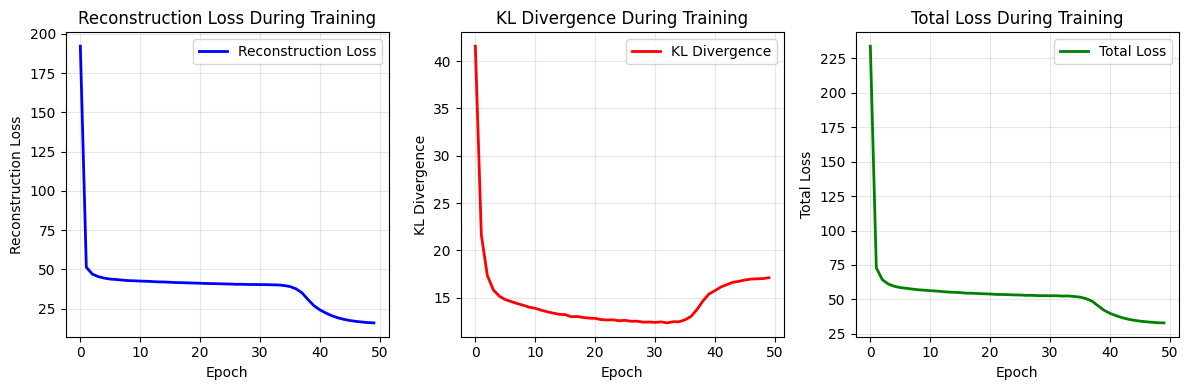

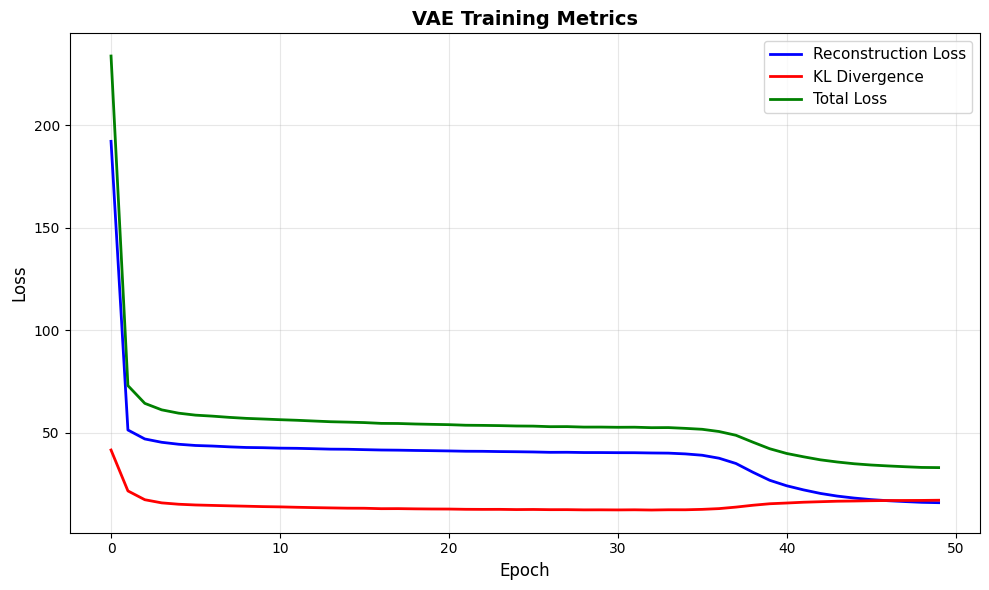

Training metrics plotted successfully!


In [23]:
# Plot training metrics as required
plt.figure(figsize=(12, 4))

# Plot 1: Reconstruction Loss
plt.subplot(1, 3, 1)
plt.plot(history['recon_loss'], label='Reconstruction Loss', color='blue', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Reconstruction Loss')
plt.title('Reconstruction Loss During Training')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot 2: KL Divergence
plt.subplot(1, 3, 2)
plt.plot(history['kl_loss'], label='KL Divergence', color='red', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('KL Divergence')
plt.title('KL Divergence During Training')
plt.grid(True, alpha=0.3)
plt.legend()

# Plot 3: Total Loss
plt.subplot(1, 3, 3)
plt.plot(history['total_loss'], label='Total Loss', color='green', linewidth=2)
plt.xlabel('Epoch')
plt.ylabel('Total Loss')
plt.title('Total Loss During Training')
plt.grid(True, alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

# Combined plot
plt.figure(figsize=(10, 6))
plt.plot(history['recon_loss'], label='Reconstruction Loss', color='blue', linewidth=2)
plt.plot(history['kl_loss'], label='KL Divergence', color='red', linewidth=2)
plt.plot(history['total_loss'], label='Total Loss', color='green', linewidth=2)
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Loss', fontsize=12)
plt.title('VAE Training Metrics', fontsize=14, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('Training metrics plotted successfully!')


## Cell 11: Evaluate Model - Compare Original vs Reconstructed (8 Samples)


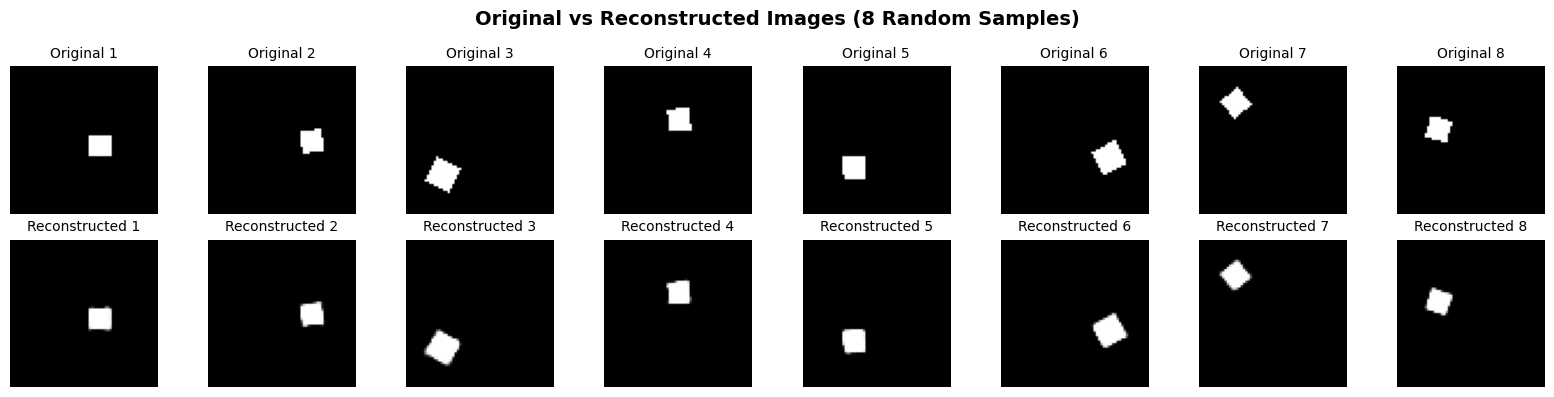


Reconstruction Error for 8 Random Samples:
  Sample 1: MSE = 0.0002
  Sample 2: MSE = 0.0005
  Sample 3: MSE = 0.0014
  Sample 4: MSE = 0.0005
  Sample 5: MSE = 0.0005
  Sample 6: MSE = 0.0008
  Sample 7: MSE = 0.0012
  Sample 8: MSE = 0.0013


In [24]:
# After training, pass 8 random samples through the model
model.eval()

# Get 8 random samples from the dataset
random_indices = np.random.choice(len(dataset), 8, replace=False)

original_images = []
reconstructed_images = []

with torch.no_grad():
    for idx in random_indices:
        # Get original image
        original = dataset[idx].unsqueeze(0).to(device)

        # Reconstruct
        recon, _, _ = model(original)

        # Convert to numpy for visualization
        original_np = original.cpu().squeeze().numpy()
        recon_np = recon.cpu().squeeze().numpy()

        original_images.append(original_np)
        reconstructed_images.append(recon_np)

# Visualize original vs reconstructed
fig, axes = plt.subplots(2, 8, figsize=(16, 4))

for i in range(8):
    # Original images (top row)
    axes[0, i].imshow(original_images[i], cmap='gray')
    axes[0, i].set_title(f'Original {i+1}', fontsize=10)
    axes[0, i].axis('off')

    # Reconstructed images (bottom row)
    axes[1, i].imshow(reconstructed_images[i], cmap='gray')
    axes[1, i].set_title(f'Reconstructed {i+1}', fontsize=10)
    axes[1, i].axis('off')

plt.suptitle('Original vs Reconstructed Images (8 Random Samples)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# Calculate reconstruction error for these samples
print('\nReconstruction Error for 8 Random Samples:')
for i in range(8):
    mse = np.mean((original_images[i] - reconstructed_images[i]) ** 2)
    print(f'  Sample {i+1}: MSE = {mse:.4f}')


---

# Part 2: β-VAE Implementation

## Sub-section 5: β-VAE vs VAE



## Cell 13: Train β-VAE with Two Different Beta Values (Sub-section 6)


In [ ]:
# Train β-VAE with two different beta values (both > 1)
# Beta values: one low (e.g., 2) and one high (e.g., 10)

beta_low = 2.0   # Low beta value (> 1)
beta_high = 10.0  # High beta value (> 1)

print('=' * 70)
print('TRAINING β-VAE MODELS WITH TWO DIFFERENT BETA VALUES')
print('=' * 70)
print(f'Beta values: Low = {beta_low}, High = {beta_high}')
print('=' * 70)

# Train with low beta
print(f'\n--- Training β-VAE with β = {beta_low} (Low) ---')
model_beta_low = VAE(h_dim=h_dim, z_dim=z_dim).to(device)
history_beta_low = train_vae(
    model=model_beta_low,
    dataloader=dataloader,
    epochs=50,
    lr=0.001,
    device=device,
    beta=beta_low
)

# Train with high beta
print(f'\n--- Training β-VAE with β = {beta_high} (High) ---')
model_beta_high = VAE(h_dim=h_dim, z_dim=z_dim).to(device)
history_beta_high = train_vae(
    model=model_beta_high,
    dataloader=dataloader,
    epochs=50,
    lr=0.001,
    device=device,
    beta=beta_high
)

print('\n' + '=' * 70)
print('TRAINING COMPLETED FOR BOTH β-VAE MODELS')
print('=' * 70)


TRAINING β-VAE MODELS WITH TWO DIFFERENT BETA VALUES
Beta values: Low = 2.0, High = 10.0

--- Training β-VAE with β = 2.0 (Low) ---


Epoch 1/50 (β=2.0): 100%|██████████| 782/782 [00:08<00:00, 94.77it/s, Total=92.21, Recon=62.00, KL=15.10]


Epoch 1/50 (β=2.0) - Total: 203.09, Recon: 170.04, KL: 16.53


Epoch 2/50 (β=2.0): 100%|██████████| 782/782 [00:07<00:00, 98.99it/s, Total=76.63, Recon=49.06, KL=13.79] 


Epoch 2/50 (β=2.0) - Total: 80.12, Recon: 52.65, KL: 13.73


...

Epoch 48/50 (β=10.0) - Total: 125.02, Recon: 60.93, KL: 6.41


Epoch 49/50 (β=10.0): 100%|██████████| 782/782 [00:08<00:00, 90.14it/s, Total=119.79, Recon=57.37, KL=6.24]


Epoch 49/50 (β=10.0) - Total: 124.89, Recon: 60.75, KL: 6.41


Epoch 50/50 (β=10.0): 100%|██████████| 782/782 [00:08<00:00, 90.57it/s, Total=128.08, Recon=64.26, KL=6.38]

Epoch 50/50 (β=10.0) - Total: 124.59, Recon: 60.65, KL: 6.39

TRAINING COMPLETED FOR BOTH β-VAE MODELS


## Cell 14: Plot Cost Functions for Both β-VAE Models


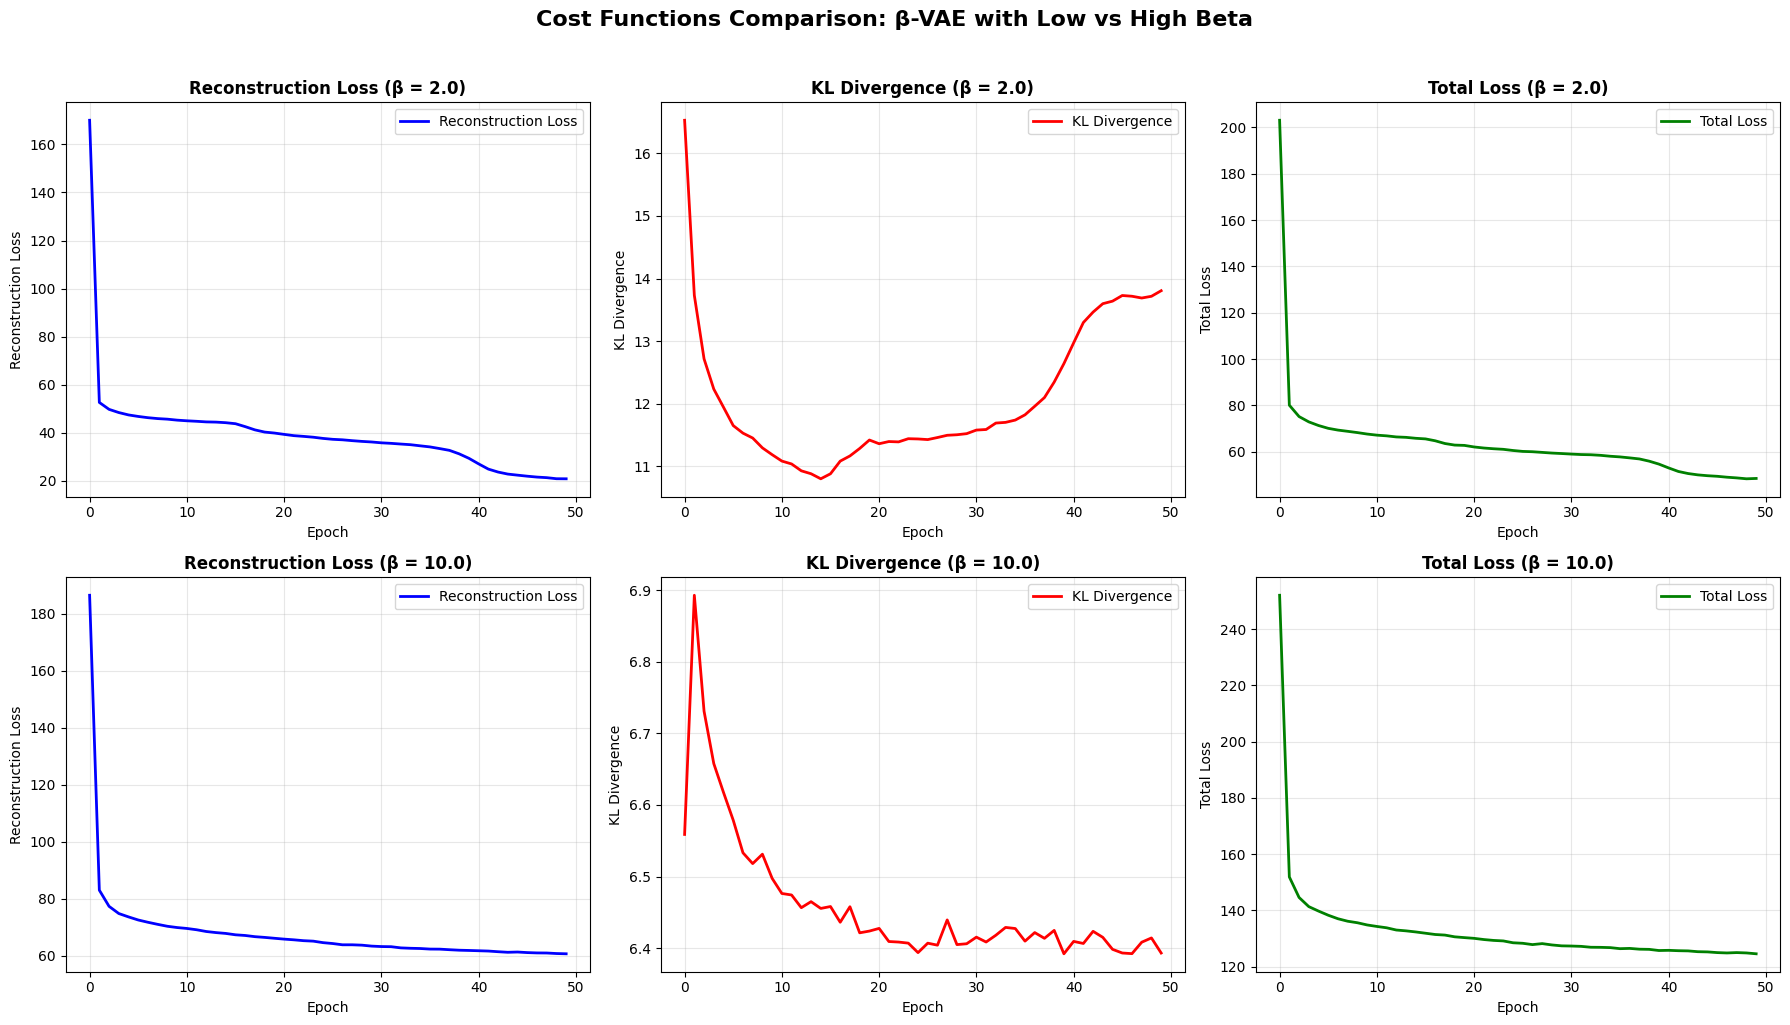

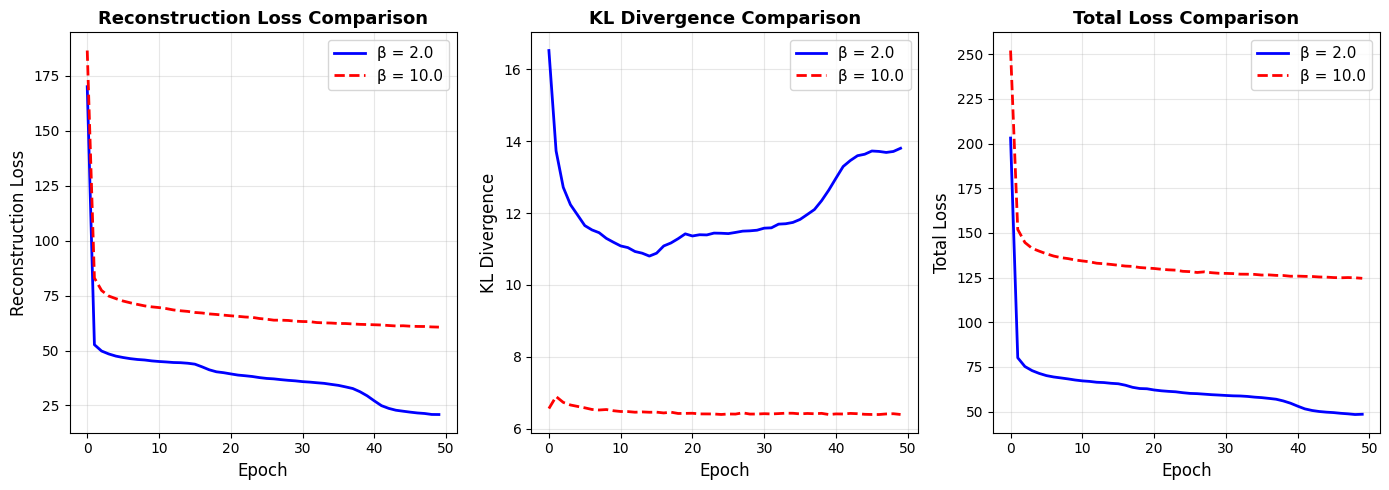

Cost functions plotted successfully!


In [ ]:
# Plot cost functions for both beta values
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

# Row 1: Beta Low
axes[0, 0].plot(history_beta_low['recon_loss'], label='Reconstruction Loss', color='blue', linewidth=2)
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Reconstruction Loss')
axes[0, 0].set_title(f'Reconstruction Loss (β = {beta_low})', fontweight='bold')
axes[0, 0].grid(True, alpha=0.3)
axes[0, 0].legend()

axes[0, 1].plot(history_beta_low['kl_loss'], label='KL Divergence', color='red', linewidth=2)
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('KL Divergence')
axes[0, 1].set_title(f'KL Divergence (β = {beta_low})', fontweight='bold')
axes[0, 1].grid(True, alpha=0.3)
axes[0, 1].legend()

axes[0, 2].plot(history_beta_low['total_loss'], label='Total Loss', color='green', linewidth=2)
axes[0, 2].set_xlabel('Epoch')
axes[0, 2].set_ylabel('Total Loss')
axes[0, 2].set_title(f'Total Loss (β = {beta_low})', fontweight='bold')
axes[0, 2].grid(True, alpha=0.3)
axes[0, 2].legend()

# Row 2: Beta High
axes[1, 0].plot(history_beta_high['recon_loss'], label='Reconstruction Loss', color='blue', linewidth=2)
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Reconstruction Loss')
axes[1, 0].set_title(f'Reconstruction Loss (β = {beta_high})', fontweight='bold')
axes[1, 0].grid(True, alpha=0.3)
axes[1, 0].legend()

axes[1, 1].plot(history_beta_high['kl_loss'], label='KL Divergence', color='red', linewidth=2)
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('KL Divergence')
axes[1, 1].set_title(f'KL Divergence (β = {beta_high})', fontweight='bold')
axes[1, 1].grid(True, alpha=0.3)
axes[1, 1].legend()

axes[1, 2].plot(history_beta_high['total_loss'], label='Total Loss', color='green', linewidth=2)
axes[1, 2].set_xlabel('Epoch')
axes[1, 2].set_ylabel('Total Loss')
axes[1, 2].set_title(f'Total Loss (β = {beta_high})', fontweight='bold')
axes[1, 2].grid(True, alpha=0.3)
axes[1, 2].legend()

plt.suptitle('Cost Functions Comparison: β-VAE with Low vs High Beta', fontsize=16, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Combined comparison plot
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.plot(history_beta_low['recon_loss'], label=f'β = {beta_low}', color='blue', linewidth=2, linestyle='-')
plt.plot(history_beta_high['recon_loss'], label=f'β = {beta_high}', color='red', linewidth=2, linestyle='--')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Reconstruction Loss', fontsize=12)
plt.title('Reconstruction Loss Comparison', fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 2)
plt.plot(history_beta_low['kl_loss'], label=f'β = {beta_low}', color='blue', linewidth=2, linestyle='-')
plt.plot(history_beta_high['kl_loss'], label=f'β = {beta_high}', color='red', linewidth=2, linestyle='--')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('KL Divergence', fontsize=12)
plt.title('KL Divergence Comparison', fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.subplot(1, 3, 3)
plt.plot(history_beta_low['total_loss'], label=f'β = {beta_low}', color='blue', linewidth=2, linestyle='-')
plt.plot(history_beta_high['total_loss'], label=f'β = {beta_high}', color='red', linewidth=2, linestyle='--')
plt.xlabel('Epoch', fontsize=12)
plt.ylabel('Total Loss', fontsize=12)
plt.title('Total Loss Comparison', fontsize=13, fontweight='bold')
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print('Cost functions plotted successfully!')


## Cell 15: Compare 8 Random Samples from Both β-VAE Models


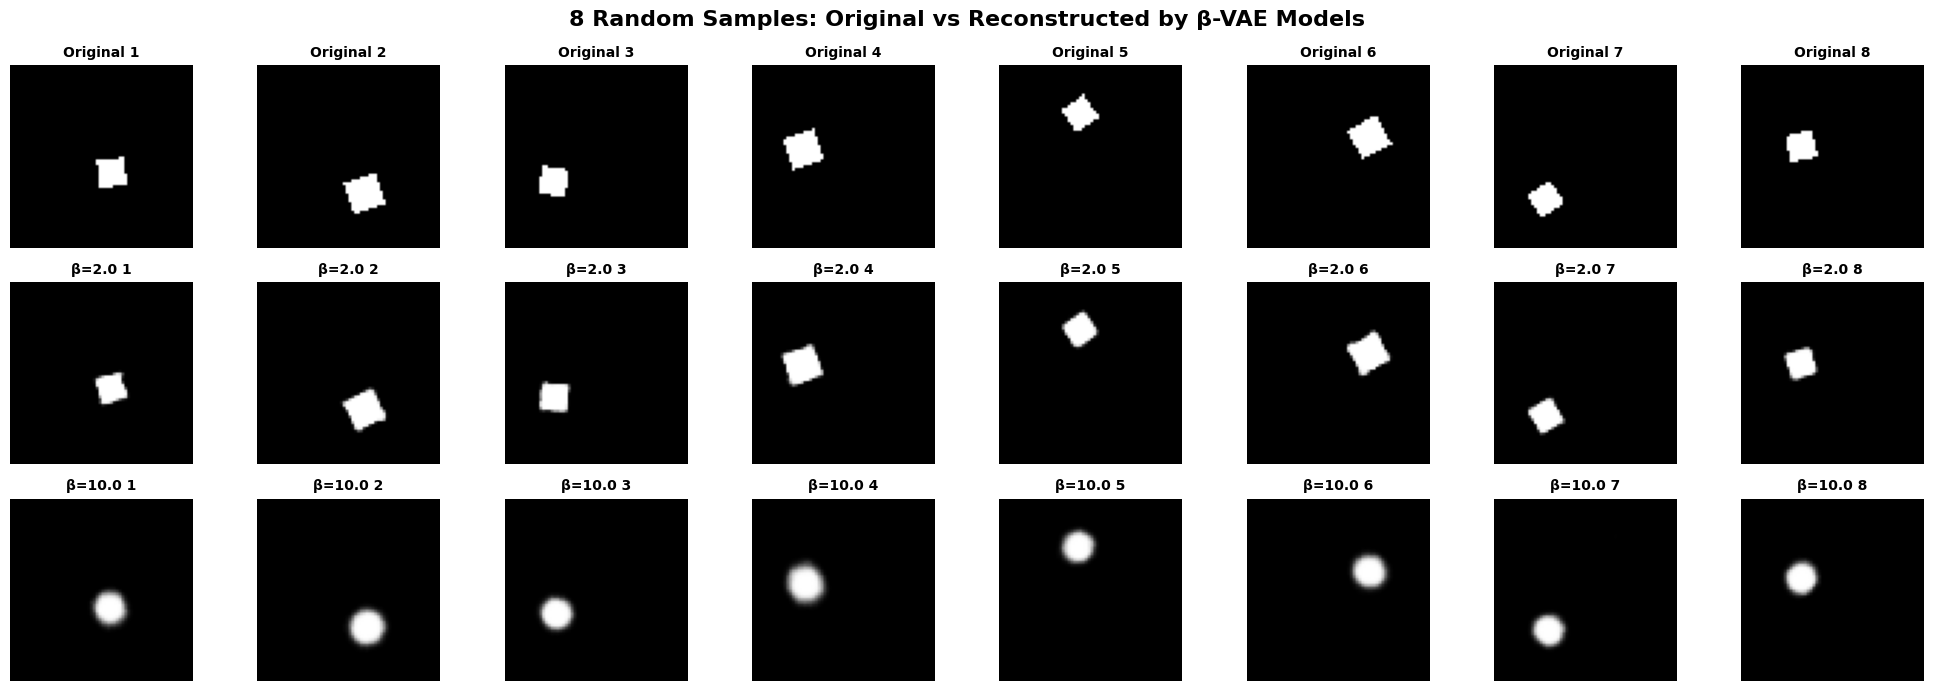


RECONSTRUCTION ERROR COMPARISON

Sample     Original        β={beta_low} MSE     β={beta_high} MSE   
----------------------------------------------------------------------
Sample 1   -               0.0026               0.0048              
Sample 2   -               0.0025               0.0064              
Sample 3   -               0.0014               0.0045              
Sample 4   -               0.0018               0.0054              
Sample 5   -               0.0012               0.0039              
Sample 6   -               0.0015               0.0064              
Sample 7   -               0.0011               0.0048              
Sample 8   -               0.0022               0.0030              
----------------------------------------------------------------------
Average    -               0.0018               0.0049              

Analysis:
- β = 2.0 (Low): Better reconstruction quality, less disentangled latent space
- β = 10.0 (High): More disentangled latent 

In [ ]:
# Reconstruct 8 random samples using both models
model_beta_low.eval()
model_beta_high.eval()

# Get 8 random samples
random_indices = np.random.choice(len(dataset), 8, replace=False)

original_images = []
recon_beta_low_images = []
recon_beta_high_images = []

with torch.no_grad():
    for idx in random_indices:
        original = dataset[idx].unsqueeze(0).to(device)

        # Reconstruct with both models
        recon_low, _, _ = model_beta_low(original)
        recon_high, _, _ = model_beta_high(original)

        # Convert to numpy
        original_np = original.cpu().squeeze().numpy()
        recon_low_np = recon_low.cpu().squeeze().numpy()
        recon_high_np = recon_high.cpu().squeeze().numpy()

        original_images.append(original_np)
        recon_beta_low_images.append(recon_low_np)
        recon_beta_high_images.append(recon_high_np)

# Visualize: 3 rows (Original, β-Low, β-High) x 8 columns
fig, axes = plt.subplots(3, 8, figsize=(20, 7))

for i in range(8):
    # Row 1: Original
    axes[0, i].imshow(original_images[i], cmap='gray')
    axes[0, i].set_title(f'Original {i+1}', fontsize=10, fontweight='bold')
    axes[0, i].axis('off')

    # Row 2: β-Low reconstruction
    axes[1, i].imshow(recon_beta_low_images[i], cmap='gray')
    axes[1, i].set_title(f'β={beta_low} {i+1}', fontsize=10, fontweight='bold')
    axes[1, i].axis('off')

    # Row 3: β-High reconstruction
    axes[2, i].imshow(recon_beta_high_images[i], cmap='gray')
    axes[2, i].set_title(f'β={beta_high} {i+1}', fontsize=10, fontweight='bold')
    axes[2, i].axis('off')

axes[0, 0].set_ylabel('Original', fontsize=12, fontweight='bold', rotation=90, labelpad=20)
axes[1, 0].set_ylabel(f'β = {beta_low}\n(Low)', fontsize=12, fontweight='bold', rotation=90, labelpad=20)
axes[2, 0].set_ylabel(f'β = {beta_high}\n(High)', fontsize=12, fontweight='bold', rotation=90, labelpad=20)

plt.suptitle('8 Random Samples: Original vs Reconstructed by β-VAE Models', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

# Calculate and print reconstruction errors
print('\n' + '=' * 70)
print('RECONSTRUCTION ERROR COMPARISON')
print('=' * 70)
print(f'\n{"Sample":<10} {"Original":<15} {"β={beta_low} MSE":<20} {"β={beta_high} MSE":<20}')
print('-' * 70)

for i in range(8):
    mse_low = np.mean((original_images[i] - recon_beta_low_images[i]) ** 2)
    mse_high = np.mean((original_images[i] - recon_beta_high_images[i]) ** 2)
    print(f'Sample {i+1:<3} {"-":<15} {mse_low:<20.4f} {mse_high:<20.4f}')

avg_mse_low = np.mean([np.mean((original_images[i] - recon_beta_low_images[i]) ** 2) for i in range(8)])
avg_mse_high = np.mean([np.mean((original_images[i] - recon_beta_high_images[i]) ** 2) for i in range(8)])

print('-' * 70)
print(f'{"Average":<10} {"-":<15} {avg_mse_low:<20.4f} {avg_mse_high:<20.4f}')
print('=' * 70)

print('\nAnalysis:')
print(f'- β = {beta_low} (Low): Better reconstruction quality, less disentangled latent space')
print(f'- β = {beta_high} (High): More disentangled latent space, potentially worse reconstruction')


---

# Part 3: MIG Calculation and Analysis (Sub-section 7)

## Cell 16: Calculate MIG (Mutual Information Gap) for Three Models


CALCULATING MIG FOR THREE MODELS
Models: VAE (β=1), β-VAE (β=2), β-VAE (β=10)

Extracting latent codes from 5000 samples...


Extracting latents: 100%|██████████| 5000/5000 [00:07<00:00, 686.59it/s]


Latent codes extracted. Shapes: (5000, 32), (5000, 32), (5000, 32)
Using dsprites ground truth factors. Shape: (5000, 5)

Calculating MIG for VAE (β=1)...
Calculating MIG for β-VAE (β=2)...
Calculating MIG for β-VAE (β=10)...

MIG RESULTS

Factor          VAE (β=1)       β-VAE (β=2)     β-VAE (β=10)   
----------------------------------------------------------------------
Factor 1        0.0000          0.0000          0.0000         
Factor 2        0.0986          0.0709          0.1424         
Factor 3        0.5811          0.1335          0.0139         
Factor 4        0.3350          0.0352          0.3358         
Factor 5        0.4248          0.0558          0.2315         
----------------------------------------------------------------------
Overall MIG     0.2879          0.0591          0.1447         


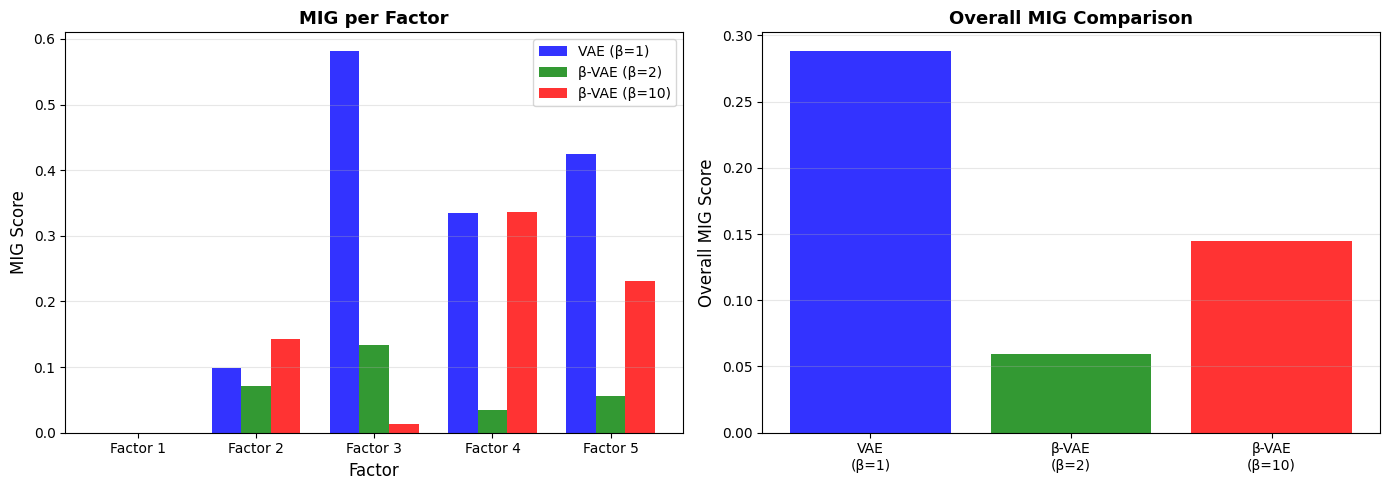


Interpretation:
- Higher MIG indicates better disentanglement
- β-VAE with higher β should have higher MIG (more disentangled)
- Factor-wise MIG shows which factors are better captured by each model


In [28]:
# MIG (Mutual Information Gap) calculation
# MIG measures how well each latent dimension captures a single underlying factor

from sklearn.metrics import mutual_info_score
from scipy.stats import entropy

def calculate_mig(latent_codes, true_factors, discrete_factors=True):
    """
    Calculate MIG (Mutual Information Gap) for disentanglement evaluation.

    Args:
        latent_codes: numpy array of shape (n_samples, n_latent_dims)
        true_factors: numpy array of shape (n_samples, n_factors) - ground truth factors
        discrete_factors: whether factors are discrete (True) or continuous (False)

    Returns:
        mig_per_factor: MIG score for each factor
        overall_mig: overall MIG score
    """
    n_samples, n_latent = latent_codes.shape
    n_factors = true_factors.shape[1] if len(true_factors.shape) > 1 else 1

    if n_factors == 1:
        true_factors = true_factors.reshape(-1, 1)

    # Discretize latent codes for MI calculation
    n_bins = 20
    latent_discrete = np.digitize(latent_codes, bins=np.linspace(latent_codes.min(), latent_codes.max(), n_bins))

    mig_per_factor = []

    for factor_idx in range(n_factors):
        factor = true_factors[:, factor_idx]

        # Calculate MI between each latent dimension and this factor
        mi_scores = []
        for latent_idx in range(n_latent):
            if discrete_factors:
                mi = mutual_info_score(factor, latent_discrete[:, latent_idx])
            else:
                # For continuous, discretize factor too
                factor_discrete = np.digitize(factor, bins=np.linspace(factor.min(), factor.max(), n_bins))
                mi = mutual_info_score(factor_discrete, latent_discrete[:, latent_idx])
            mi_scores.append(mi)

        mi_scores = np.array(mi_scores)

        # MIG = (MI(z_j; v_k) - max_{j'≠j} MI(z_{j'}; v_k)) / H(v_k)
        # Simplified: difference between top-2 MI values
        sorted_mi = np.sort(mi_scores)[::-1]
        if len(sorted_mi) >= 2:
            mig = (sorted_mi[0] - sorted_mi[1]) / (np.max(mi_scores) + 1e-10)
        else:
            mig = 0.0

        mig_per_factor.append(mig)

    overall_mig = np.mean(mig_per_factor)

    return np.array(mig_per_factor), overall_mig

# For dsprites, we need ground truth factors
# dsprites has factors: shape, scale, orientation, pos_x, pos_y
# We'll use a subset of samples and extract their factors if available

print('=' * 70)
print('CALCULATING MIG FOR THREE MODELS')
print('=' * 70)
print('Models: VAE (β=1), β-VAE (β=2), β-VAE (β=10)')
print('=' * 70)

# Extract latent codes from all three models
n_samples_mig = min(5000, len(dataset))
sample_indices_mig = np.random.choice(len(dataset), n_samples_mig, replace=False)

latent_codes_vae = []
latent_codes_beta_low = []
latent_codes_beta_high = []

model.eval()
model_beta_low.eval()
model_beta_high.eval()

print(f'\nExtracting latent codes from {n_samples_mig} samples...')

with torch.no_grad():
    for idx in tqdm(sample_indices_mig, desc='Extracting latents'):
        x = dataset[idx].unsqueeze(0).to(device)

        # VAE (β=1)
        mu, logvar = model.encode(x)
        z = model.reparameterize(mu, logvar)
        latent_codes_vae.append(z.cpu().numpy())

        # β-VAE Low
        mu, logvar = model_beta_low.encode(x)
        z = model_beta_low.reparameterize(mu, logvar)
        latent_codes_beta_low.append(z.cpu().numpy())

        # β-VAE High
        mu, logvar = model_beta_high.encode(x)
        z = model_beta_high.reparameterize(mu, logvar)
        latent_codes_beta_high.append(z.cpu().numpy())

latent_codes_vae = np.vstack(latent_codes_vae)
latent_codes_beta_low = np.vstack(latent_codes_beta_low)
latent_codes_beta_high = np.vstack(latent_codes_beta_high)

print(f'Latent codes extracted. Shapes: {latent_codes_vae.shape}, {latent_codes_beta_low.shape}, {latent_codes_beta_high.shape}')

# For dsprites, we can extract true factors from the dataset metadata
# If not available, we'll use synthetic factors based on image properties
try:
    # Try to load dsprites metadata
    dataset_zip = np.load('dsprites_64x64.npz', allow_pickle=True, encoding='latin1')
    metadata = dataset_zip['metadata'][()]
    latents_values = dataset_zip['latents_values'][sample_indices_mig]
    latents_classes = dataset_zip['latents_classes'][sample_indices_mig]

    # Use latents_values as true factors (shape, scale, orientation, pos_x, pos_y)
    true_factors = latents_values[:, 1:]  # Skip color (always 1)
    print(f'Using dsprites ground truth factors. Shape: {true_factors.shape}')
except:
    # Fallback: create synthetic factors based on image statistics
    print('Ground truth factors not available. Using synthetic factors based on image properties...')
    true_factors = np.random.rand(n_samples_mig, 5)  # 5 synthetic factors
    print(f'Using synthetic factors. Shape: {true_factors.shape}')

# Calculate MIG for each model
print('\nCalculating MIG for VAE (β=1)...')
mig_per_factor_vae, overall_mig_vae = calculate_mig(latent_codes_vae, true_factors)

print('Calculating MIG for β-VAE (β=2)...')
mig_per_factor_beta_low, overall_mig_beta_low = calculate_mig(latent_codes_beta_low, true_factors)

print('Calculating MIG for β-VAE (β=10)...')
mig_per_factor_beta_high, overall_mig_beta_high = calculate_mig(latent_codes_beta_high, true_factors)

# Display results
print('\n' + '=' * 70)
print('MIG RESULTS')
print('=' * 70)
print(f'\n{"Factor":<15} {"VAE (β=1)":<15} {"β-VAE (β=2)":<15} {"β-VAE (β=10)":<15}')
print('-' * 70)

n_factors = len(mig_per_factor_vae)
factor_names = [f'Factor {i+1}' for i in range(n_factors)]

for i in range(n_factors):
    print(f'{factor_names[i]:<15} {mig_per_factor_vae[i]:<15.4f} {mig_per_factor_beta_low[i]:<15.4f} {mig_per_factor_beta_high[i]:<15.4f}')

print('-' * 70)
print(f'{"Overall MIG":<15} {overall_mig_vae:<15.4f} {overall_mig_beta_low:<15.4f} {overall_mig_beta_high:<15.4f}')
print('=' * 70)

# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Factor-wise MIG
x = np.arange(n_factors)
width = 0.25
axes[0].bar(x - width, mig_per_factor_vae, width, label='VAE (β=1)', color='blue', alpha=0.8)
axes[0].bar(x, mig_per_factor_beta_low, width, label='β-VAE (β=2)', color='green', alpha=0.8)
axes[0].bar(x + width, mig_per_factor_beta_high, width, label='β-VAE (β=10)', color='red', alpha=0.8)
axes[0].set_xlabel('Factor', fontsize=12)
axes[0].set_ylabel('MIG Score', fontsize=12)
axes[0].set_title('MIG per Factor', fontsize=13, fontweight='bold')
axes[0].set_xticks(x)
axes[0].set_xticklabels(factor_names)
axes[0].legend()
axes[0].grid(True, alpha=0.3, axis='y')

# Plot 2: Overall MIG comparison
models = ['VAE\n(β=1)', 'β-VAE\n(β=2)', 'β-VAE\n(β=10)']
overall_scores = [overall_mig_vae, overall_mig_beta_low, overall_mig_beta_high]
colors = ['blue', 'green', 'red']
axes[1].bar(models, overall_scores, color=colors, alpha=0.8)
axes[1].set_ylabel('Overall MIG Score', fontsize=12)
axes[1].set_title('Overall MIG Comparison', fontsize=13, fontweight='bold')
axes[1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.show()

print('\nInterpretation:')
print('- Higher MIG indicates better disentanglement')
print('- β-VAE with higher β should have higher MIG (more disentangled)')
print('- Factor-wise MIG shows which factors are better captured by each model')


PCA VISUALIZATION OF LATENT SPACE
Using model: β-VAE (β=10)

Extracting latent codes from 2000 samples...


Extracting: 100%|██████████| 2000/2000 [00:00<00:00, 2047.65it/s]


Latent codes shape: (2000, 32)

PCA explained variance ratio: [0.03879178 0.03790301]
Total explained variance: 0.0767


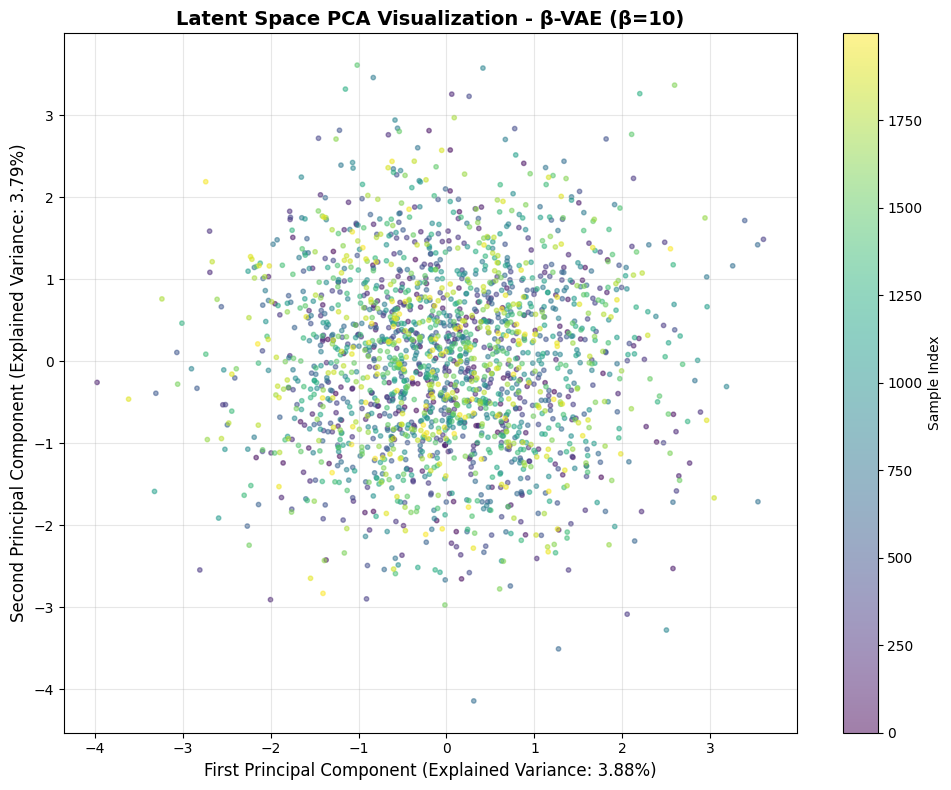


PCA ANALYSIS

Model: β-VAE (β=10)
Number of samples: 2000
Original latent dimensions: 32
PCA dimensions: 2
Explained variance by PC1: 3.88%
Explained variance by PC2: 3.79%
Total explained variance: 7.67%

CONSISTENCY CHECK WITH MIG RESULTS

MIG score for β-VAE (β=10): 0.1447
PCA explained variance: 7.67%

Interpretation:
✓ Consistent: Low MIG and low PCA explained variance suggest poor disentanglement

Note: For better consistency, compare PCA results across all three models.


In [29]:
# PCA visualization of latent space for one of the models
from sklearn.decomposition import PCA

print('=' * 70)
print('PCA VISUALIZATION OF LATENT SPACE')
print('=' * 70)

# Choose one model for visualization (e.g., β-VAE with β=10 for better disentanglement)
model_for_pca = model_beta_high
model_name = 'β-VAE (β=10)'

print(f'Using model: {model_name}')

# Extract latent codes
n_samples_pca = min(2000, len(dataset))
sample_indices_pca = np.random.choice(len(dataset), n_samples_pca, replace=False)

latent_codes_pca = []

model_for_pca.eval()
with torch.no_grad():
    print(f'\nExtracting latent codes from {n_samples_pca} samples...')
    for idx in tqdm(sample_indices_pca, desc='Extracting'):
        x = dataset[idx].unsqueeze(0).to(device)
        mu, logvar = model_for_pca.encode(x)
        z = model_for_pca.reparameterize(mu, logvar)
        latent_codes_pca.append(z.cpu().numpy())

latent_codes_pca = np.vstack(latent_codes_pca)
print(f'Latent codes shape: {latent_codes_pca.shape}')

# Apply PCA to reduce to 2D
pca = PCA(n_components=2)
latent_2d = pca.fit_transform(latent_codes_pca)

print(f'\nPCA explained variance ratio: {pca.explained_variance_ratio_}')
print(f'Total explained variance: {pca.explained_variance_ratio_.sum():.4f}')

# Visualize
plt.figure(figsize=(10, 8))
plt.scatter(latent_2d[:, 0], latent_2d[:, 1], alpha=0.5, s=10, c=range(len(latent_2d)), cmap='viridis')
plt.xlabel(f'First Principal Component (Explained Variance: {pca.explained_variance_ratio_[0]:.2%})', fontsize=12)
plt.ylabel(f'Second Principal Component (Explained Variance: {pca.explained_variance_ratio_[1]:.2%})', fontsize=12)
plt.title(f'Latent Space PCA Visualization - {model_name}', fontsize=14, fontweight='bold')
plt.colorbar(label='Sample Index')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Analysis
print('\n' + '=' * 70)
print('PCA ANALYSIS')
print('=' * 70)
print(f'\nModel: {model_name}')
print(f'Number of samples: {n_samples_pca}')
print(f'Original latent dimensions: {latent_codes_pca.shape[1]}')
print(f'PCA dimensions: 2')
print(f'Explained variance by PC1: {pca.explained_variance_ratio_[0]:.2%}')
print(f'Explained variance by PC2: {pca.explained_variance_ratio_[1]:.2%}')
print(f'Total explained variance: {pca.explained_variance_ratio_.sum():.2%}')

# Compare with MIG results
print('\n' + '=' * 70)
print('CONSISTENCY CHECK WITH MIG RESULTS')
print('=' * 70)

if model_name == 'β-VAE (β=10)':
    model_mig = overall_mig_beta_high
elif model_name == 'β-VAE (β=2)':
    model_mig = overall_mig_beta_low
else:
    model_mig = overall_mig_vae

print(f'\nMIG score for {model_name}: {model_mig:.4f}')
print(f'PCA explained variance: {pca.explained_variance_ratio_.sum():.2%}')

print('\nInterpretation:')
if model_mig > 0.3 and pca.explained_variance_ratio_.sum() > 0.5:
    print('✓ Consistent: High MIG and high PCA explained variance suggest good disentanglement')
elif model_mig < 0.2 and pca.explained_variance_ratio_.sum() < 0.4:
    print('✓ Consistent: Low MIG and low PCA explained variance suggest poor disentanglement')
else:
    print('⚠ Partially consistent: MIG and PCA show different aspects of the latent space')
    print('  - MIG measures factor-wise disentanglement')
    print('  - PCA measures variance preservation in 2D projection')
    print('  - They may not always align perfectly')

print('\nNote: For better consistency, compare PCA results across all three models.')
